# E-commerce Customer and Product Analysis

## Objective
Explore customer demographics, loyalty tiers, product categories, and
pricing patterns using SQL and Python.

## Tools
- DuckDB: Query Parquet datasets using SQL.
- Pandas: Process and analyze query results.
- Matplotlib and Seaborn: Visualize patterns and distributions.

## Dataset
The analysis uses the synthetic e-commerce dataset containing customer,
product, category, order, order-item, payment, and return records.

## Approach
1. Load the required libraries.
2. Connect to the dataset using DuckDB.
3. Explore customer and product data with SQL.
4. Analyze query results using Pandas.
5. Create visualizations and document findings.

In [1]:
import duckdb
import pandas as pd
import matplotlib
import seaborn as sns

## 1. Database Connection and Dataset Overview

Connect DuckDB to the e-commerce dataset and inspect the available tables.
We will use SQL for data retrieval and Pandas for subsequent analysis.

In [2]:
from pathlib import Path
import duckdb

# Locate the project directory
PROJECT_DIR = Path.cwd()

# If JupyterLab was launched from another directory, locate the project manually.
if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = Path(
        r"C:\Users\Kartikey Sharma\Documents\Internship Projects\YuvaIntern Internship\Data-Science-Tool-Mastery"
    )

DATA_DIR = PROJECT_DIR / "data"

# Connect to DuckDB
con = duckdb.connect()

print("Project directory:", PROJECT_DIR)
print("Data directory exists:", DATA_DIR.exists())

# List the available Parquet files
parquet_files = sorted(DATA_DIR.glob("*.parquet"))

print("\nNumber of Parquet files:", len(parquet_files))
for file in parquet_files:
    print("-", file.name)

Project directory: C:\Users\Kartikey Sharma\Documents\Internship Projects\YuvaIntern Internship\Data-Science-Tool-Mastery
Data directory exists: True

Number of Parquet files: 7
- categories.parquet
- customers.parquet
- order_items.parquet
- orders.parquet
- payments.parquet
- products.parquet
- returns.parquet


## 2. Register Dataset Tables

Create temporary DuckDB views over the Parquet files. These views allow
us to query the dataset using SQL without copying the underlying data.

In [3]:
# Register each Parquet file as a temporary DuckDB view
table_names = [
    "categories",
    "customers",
    "order_items",
    "orders",
    "payments",
    "products",
    "returns",
]

for table in table_names:
    parquet_path = (DATA_DIR / f"{table}.parquet").as_posix()

    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW {table} AS
        SELECT * FROM read_parquet('{parquet_path}')
    """)

print("Registered tables:")

for row in con.execute("SHOW TABLES").fetchall():
    print("-", row[0])

Registered tables:
- categories
- customers
- order_items
- orders
- payments
- products
- returns


In [4]:
row_counts = con.execute("""
    SELECT 'categories' AS table_name, COUNT(*) AS row_count FROM categories
    UNION ALL
    SELECT 'customers', COUNT(*) FROM customers
    UNION ALL
    SELECT 'order_items', COUNT(*) FROM order_items
    UNION ALL
    SELECT 'orders', COUNT(*) FROM orders
    UNION ALL
    SELECT 'payments', COUNT(*) FROM payments
    UNION ALL
    SELECT 'products', COUNT(*) FROM products
    UNION ALL
    SELECT 'returns', COUNT(*) FROM returns
    ORDER BY table_name
""").df()

row_counts

,table_name,row_count
0,categories,24
1,customers,12000
2,order_items,215000
3,orders,90000
4,payments,95000
5,products,2000
6,returns,12000


## 3. Customer Demographics and Loyalty Analysis

This section explores customer geography, loyalty tiers, and marketing
preferences to understand the composition of the customer base.

### 3.1 Customer Data Overview

Inspect the customer records and identify the available attributes.

In [5]:
# Display the first five customer records
customers_df = con.execute("""
    SELECT *
    FROM customers
    LIMIT 5
""").df()

customers_df

,customer_id,first_name,last_name,email,city,country,signup_date,loyalty_tier,marketing_opt_in
0,1,Delphine,Rossi,delphine.rossi0@example.com,Bristol,GB,2023-02-13,silver,False
1,2,Bruno,Kirby,bruno.kirby1@example.com,Toronto,CA,2023-09-29,NaN,True
2,3,Bianca,Mwangi,bianca.mwangi2@example.com,Raleigh,US,2023-04-11,NaN,True
3,4,Hugo,Kirby,hugo.kirby3@example.com,Norwich,GB,2023-12-27,bronze,True
4,5,Hana,Vogt,hana.vogt4@example.com,Auckland,NZ,2025-06-01,NaN,True


In [6]:
# Inspect column names and data types
customer_profile = con.execute("""
    DESCRIBE SELECT * FROM customers
""").df()

customer_profile

,column_name,column_type,null,key,default,extra
0,customer_id,INTEGER,YES,None,None,None
1,first_name,VARCHAR,YES,None,None,None
2,last_name,VARCHAR,YES,None,None,None
3,email,VARCHAR,YES,None,None,None
4,city,VARCHAR,YES,None,None,None
5,country,VARCHAR,YES,None,None,None
6,signup_date,DATE,YES,None,None,None
7,loyalty_tier,VARCHAR,YES,None,None,None
8,marketing_opt_in,BOOLEAN,YES,None,None,None


In [7]:
# Calculate missing values for each column
customer_missing = con.execute("""
    SELECT
        COUNT(*) - COUNT(customer_id) AS missing_customer_id,
        COUNT(*) - COUNT(first_name) AS missing_first_name,
        COUNT(*) - COUNT(last_name) AS missing_last_name,
        COUNT(*) - COUNT(email) AS missing_email,
        COUNT(*) - COUNT(city) AS missing_city,
        COUNT(*) - COUNT(country) AS missing_country,
        COUNT(*) - COUNT(signup_date) AS missing_signup_date,
        COUNT(*) - COUNT(loyalty_tier) AS missing_loyalty_tier,
        COUNT(*) - COUNT(marketing_opt_in) AS missing_marketing_opt_in
    FROM customers
""").df()

customer_missing

,missing_customer_id,missing_first_name,missing_last_name,missing_email,missing_city,missing_country,missing_signup_date,missing_loyalty_tier,missing_marketing_opt_in
0,0,0,0,0,0,0,0,5296,0


### 3.2 Customer Distribution by Country

Analyze the number and percentage of customers in each country to
understand the geographical distribution of the customer base.

In [8]:
# Calculate customer counts and percentages by country
country_analysis = con.execute("""
    SELECT
        country,
        COUNT(*) AS customer_count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM customers
    GROUP BY country
    ORDER BY customer_count DESC
""").df()

country_analysis

,country,customer_count,percentage
0,US,2075,17.29
1,GB,1504,12.53
2,AU,1114,9.28
3,CA,1063,8.86
4,DE,732,6.10
5,NZ,711,5.93
6,IE,709,5.91
7,FR,704,5.87
8,NL,702,5.85
9,SE,358,2.98


### 3.3 Customer Distribution by Loyalty Tier

Examine the number and percentage of customers in each loyalty tier
to understand the composition of the customer base.

In [9]:
# Calculate customer counts and percentages by loyalty tier
loyalty_analysis = con.execute("""
    SELECT
        loyalty_tier,
        COUNT(*) AS customer_count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM customers
    GROUP BY loyalty_tier
    ORDER BY customer_count DESC
""").df()

loyalty_analysis

,loyalty_tier,customer_count,percentage
0,NaN,5296,44.13
1,bronze,4023,33.53
2,silver,1992,16.60
3,gold,689,5.74


### 3.4 Customer Data Visualization

Visualize customer distribution by country and loyalty tier to identify
the largest customer markets and understand the distribution of loyalty
membership, including missing tier information.

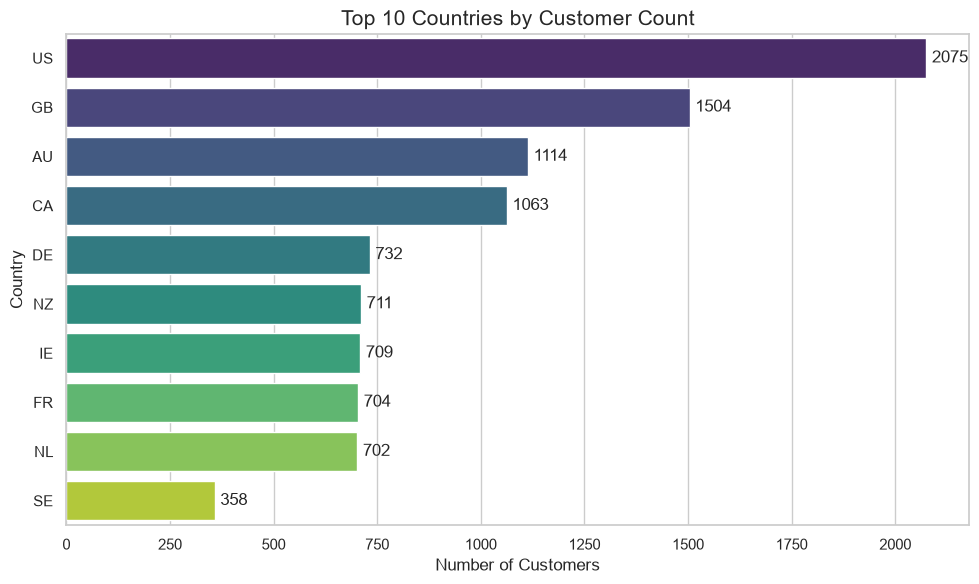

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the ten countries with the most customers
top_countries = country_analysis.head(10).copy()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_countries,
    x="customer_count",
    y="country",
    hue="country",
    palette="viridis",
    legend=False
)

ax.set_title("Top 10 Countries by Customer Count", fontsize=15)
ax.set_xlabel("Number of Customers")
ax.set_ylabel("Country")

# Display counts at the ends of the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

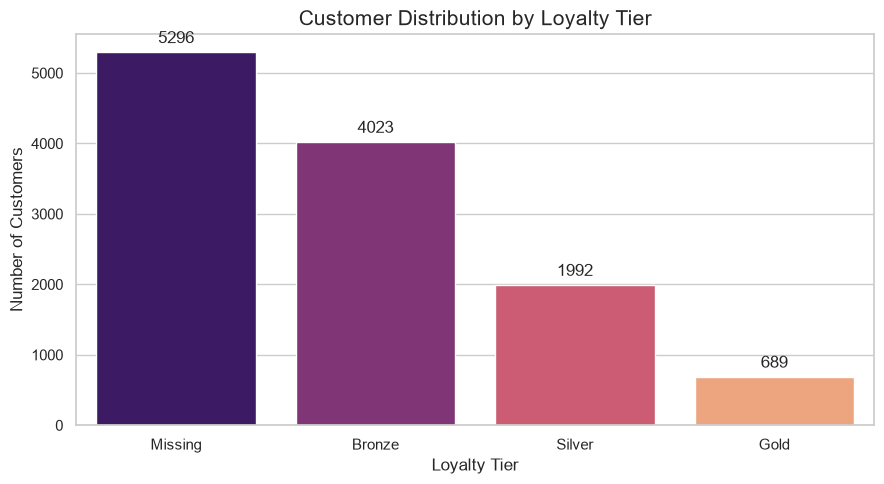

In [11]:
# Prepare a display-friendly copy of the loyalty results
loyalty_plot = loyalty_analysis.copy()

loyalty_plot["loyalty_tier"] = (
    loyalty_plot["loyalty_tier"]
    .fillna("Missing")
    .str.title()
)

# Sort tiers by customer count for a clearer chart
loyalty_plot = loyalty_plot.sort_values(
    "customer_count",
    ascending=False
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=loyalty_plot,
    x="loyalty_tier",
    y="customer_count",
    hue="loyalty_tier",
    palette="magma",
    legend=False
)

ax.set_title("Customer Distribution by Loyalty Tier", fontsize=15)
ax.set_xlabel("Loyalty Tier")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

### 3.5 Customer Marketing Preferences

Analyze customer marketing opt-in preferences to understand how many
customers have agreed to receive marketing communications.

In [12]:
# Analyze marketing opt-in preferences
marketing_analysis = con.execute("""
    SELECT
        marketing_opt_in,
        COUNT(*) AS customer_count,
        ROUND(
            COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
            2
        ) AS percentage
    FROM customers
    GROUP BY marketing_opt_in
    ORDER BY marketing_opt_in DESC
""").df()

marketing_analysis

,marketing_opt_in,customer_count,percentage
0,True,7489,62.41
1,False,4511,37.59


In [13]:
# Aggregate customer signups by month
signup_trends = con.execute("""
    SELECT
        DATE_TRUNC('month', signup_date)::DATE AS signup_month,
        COUNT(*) AS new_customers
    FROM customers
    WHERE signup_date IS NOT NULL
    GROUP BY signup_month
    ORDER BY signup_month
""").df()

signup_trends.head(10)

,signup_month,new_customers
0,2023-01-01,314
1,2023-02-01,300
2,2023-03-01,317
3,2023-04-01,293
4,2023-05-01,304
5,2023-06-01,273
6,2023-07-01,303
7,2023-08-01,314
8,2023-09-01,282
9,2023-10-01,317


In [14]:
# Summarize customer signups by year
yearly_signups = con.execute("""
    SELECT
        YEAR(signup_date) AS signup_year,
        COUNT(*) AS new_customers
    FROM customers
    WHERE signup_date IS NOT NULL
    GROUP BY signup_year
    ORDER BY signup_year
""").df()

yearly_signups

,signup_year,new_customers
0,2023,4022
1,2024,4059
2,2025,3919


### 3.7 Visualizing Marketing Preferences and Signup Trends

Visualize customer marketing opt-in preferences and monthly customer
signups to understand consent distribution and changes in registration
volume over time.

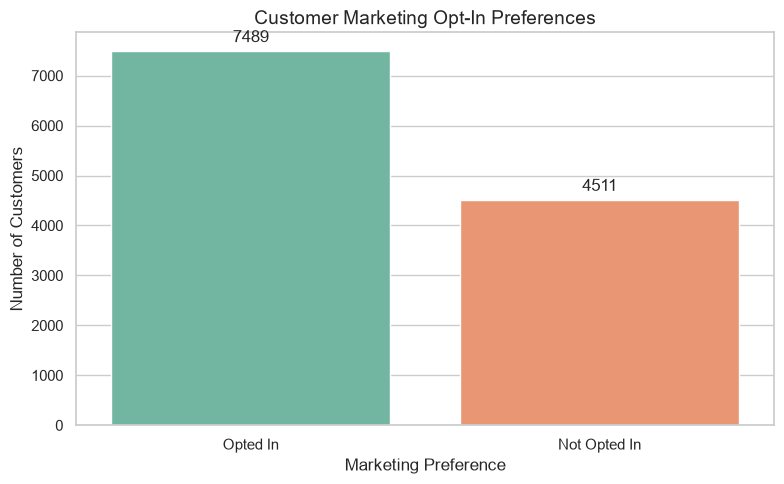

In [15]:
# Prepare readable labels for marketing preferences
marketing_plot = marketing_analysis.copy()

marketing_plot["marketing_status"] = marketing_plot[
    "marketing_opt_in"
].map({
    True: "Opted In",
    False: "Not Opted In"
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=marketing_plot,
    x="marketing_status",
    y="customer_count",
    hue="marketing_status",
    palette="Set2",
    legend=False
)

ax.set_title("Customer Marketing Opt-In Preferences", fontsize=14)
ax.set_xlabel("Marketing Preference")
ax.set_ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

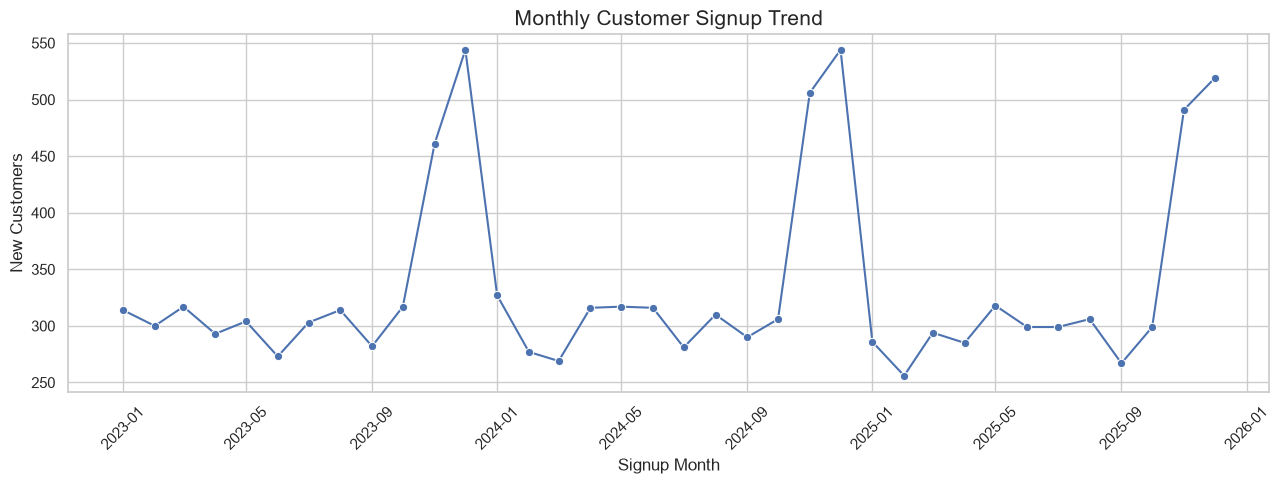

In [16]:
# Plot monthly customer signups
plt.figure(figsize=(13, 5))

ax = sns.lineplot(
    data=signup_trends,
    x="signup_month",
    y="new_customers",
    marker="o"
)

ax.set_title("Monthly Customer Signup Trend", fontsize=15)
ax.set_xlabel("Signup Month")
ax.set_ylabel("New Customers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
# Inspect the available signup date range
signup_date_range = con.execute("""
    SELECT
        MIN(signup_date) AS earliest_signup,
        MAX(signup_date) AS latest_signup,
        COUNT(*) AS customers_with_signup_dates
    FROM customers
    WHERE signup_date IS NOT NULL
""").df()

signup_date_range

,earliest_signup,latest_signup,customers_with_signup_dates
0,2023-01-01,2025-12-31,12000


In [18]:
# Identify the ten months with the highest signup counts
top_signup_months = signup_trends.nlargest(
    10,
    "new_customers"
).sort_values(
    "new_customers",
    ascending=False
)

top_signup_months

,signup_month,new_customers
11,2023-12-01,544
23,2024-12-01,544
35,2025-12-01,519
22,2024-11-01,506
34,2025-11-01,491
10,2023-11-01,461
12,2024-01-01,327
28,2025-05-01,318
2,2023-03-01,317
9,2023-10-01,317


In [19]:
# Compare signup counts by calendar month across years
monthly_signup_comparison = con.execute("""
    SELECT
        MONTH(signup_date) AS month_number,
        STRFTIME(signup_date, '%B') AS month_name,
        SUM(CASE WHEN YEAR(signup_date) = 2023 THEN 1 ELSE 0 END)
            AS signups_2023,
        SUM(CASE WHEN YEAR(signup_date) = 2024 THEN 1 ELSE 0 END)
            AS signups_2024,
        SUM(CASE WHEN YEAR(signup_date) = 2025 THEN 1 ELSE 0 END)
            AS signups_2025
    FROM customers
    WHERE signup_date IS NOT NULL
    GROUP BY month_number, month_name
    ORDER BY month_number
""").df()

monthly_signup_comparison

,month_number,month_name,signups_2023,signups_2024,signups_2025
0,1,January,314.0,327.0,286.0
1,2,February,300.0,277.0,256.0
2,3,March,317.0,269.0,294.0
3,4,April,293.0,316.0,285.0
4,5,May,304.0,317.0,318.0
5,6,June,273.0,316.0,299.0
6,7,July,303.0,281.0,299.0
7,8,August,314.0,310.0,306.0
8,9,September,282.0,290.0,267.0
9,10,October,317.0,306.0,299.0


### 3.8 Key Findings and Conclusions

#### Customer Geography
- The dataset contains 12,000 customers across 17 countries.
- The United States has the largest customer base, with 2,075 customers (17.29%).
- The top four countries account for approximately 47.96% of customers.

#### Loyalty Tiers
- 5,296 customers (44.13%) have a missing loyalty tier.
- Bronze is the most common recorded tier, with 4,023 customers.
- Missing loyalty information should be investigated before evaluating
  loyalty-program performance.

#### Marketing Preferences
- 7,489 customers (62.41%) opted in to marketing communications.
- 4,511 customers (37.59%) did not opt in.

#### Customer Signup Trends
- The dataset covers customer signup dates from January 2023 through
  December 2025.
- Annual signups were 4,022 in 2023, 4,059 in 2024, and 3,919 in 2025.
- November and December consistently recorded higher signup counts
  than most other months.
- December had the highest monthly signup count in each of the three years.

#### Limitations
- The dataset shows signup patterns but does not establish their causes.
- Missing loyalty tiers may affect conclusions about loyalty membership.
- Additional data would be needed to evaluate marketing effectiveness
  or explain year-end signup increases.